# Chương 3: Phân Tích Dữ Liệu Khám Phá (EDA) & Tiền Xử Lý Chống Rò Rỉ
## Sequence-to-Sequence Weather Forecasting — Jena Climate (Topic 5)

**Mục tiêu:** Trực quan hóa dữ liệu thời tiết Jena Climate và triển khai **Quy trình 4 pha chống rò rỉ (Strict Anti-Leakage)** cho bài toán dự báo **168 giờ quá khứ $\rightarrow$ 72 giờ tương lai**:
1. **Lọc lỗi cảm biến** (`-9999.0 -> NaN`) và gom mẫu `1h`.
2. **Pha 1 (Split First):** Chia tuần tự theo thời gian **70% Train — 15% Val — 15% Test**.
3. **Pha 2 (EDA on Train Only):** Chỉ vẽ biểu đồ & tính thống kê trên **70% tập Train**.
4. **Pha 3 & Pha 4:** Chuẩn hóa `StandardScaler` chỉ `fit` trên Train + cắt cửa sổ trượt độc lập + kiểm định `verify_zero_leakage()`.

In [1]:
%matplotlib inline
import os, sys, yaml
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams["figure.dpi"] = 110
sns.set_style("whitegrid")

from src.data_module import JenaDataModule
from src.eda import (
    plot_wind_anomalies, plot_data_split_timeline, plot_temperature_trend,
    plot_temperature_distribution, plot_temperature_regime_pie,
    plot_seasonal_monthly_cycle, plot_diurnal_cycle,
    plot_correlation_heatmap, plot_target_correlations,
    plot_scatter_relationships, plot_wind_rose, plot_autocorrelation,
    plot_scaling_comparison, plot_sliding_window_example, summarize_eda_insights,
)
print("Sẵn sàng chạy EDA!")

Sẵn sàng chạy EDA!


---
## Phần 1: Nạp Dữ Liệu Gốc & Phát Hiện Cảm Biến Lỗi (`-9999.0`)

Dữ liệu gốc: 420,551 dòng x 15 cột


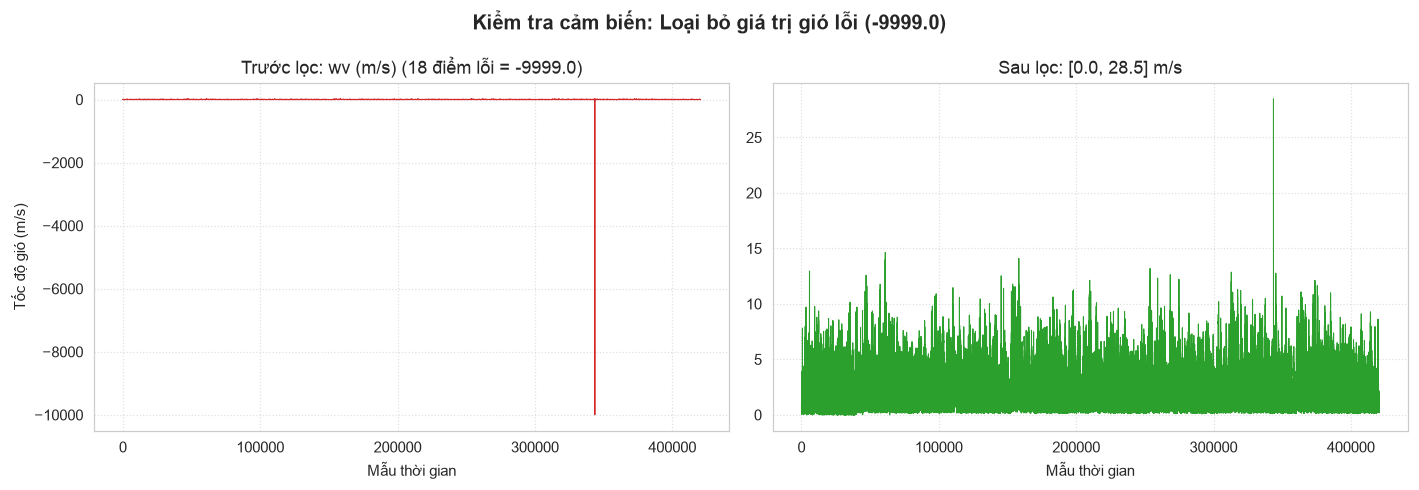

In [2]:
with open("../configs/config.yaml", "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)["data"]

raw_csv_path = os.path.join("..", cfg["raw_csv_path"])
dm = JenaDataModule(
    raw_csv_path=raw_csv_path,
    seq_len=cfg["seq_len"],
    pred_len=cfg["pred_len"],
    target_col=cfg["target_col"],
    train_ratio=cfg["train_ratio"],
    val_ratio=cfg["val_ratio"],
    test_ratio=cfg["test_ratio"],
    resample_rule=cfg["resample_rule"],
    invalid_wind_val=cfg.get("invalid_wind_val", -9999.0),
)

raw_df = pd.read_csv(raw_csv_path)
print(f"Dữ liệu gốc: {raw_df.shape[0]:,} dòng x {raw_df.shape[1]} cột")
plot_wind_anomalies(raw_df, invalid_val=dm.invalid_wind_val)

**Giải thích Biểu đồ 1 (Cảm biến gió lỗi `-9999.0`):**
- **Quan sát:** Bên trái xuất hiện các điểm cực đoan `-9999.0` kéo dẹt toàn bộ dải tốc độ gió thật (`0–25 m/s`) xuống sát `0`. Bên phải sau khi thay `-9999.0 -> NaN`, tín hiệu gió trở về miền vật lý hợp lệ.
- **Ý nghĩa cho mô hình:** Bắt buộc lọc lỗi trước khi gom mẫu `1h` và chuẩn hóa, nếu không `StandardScaler` sẽ bị méo Mean/Std và gây nổ gradient khi huấn luyện.

---
## Phần 2: Pha 1 — Resample `1h` & Chia Tuần Tự Theo Thời Gian (Split First)

Tổng sau Resample 1h: 70,129 giờ
  - Train (70%): 49,090h (2009-01-01 00:00:00 -> 2014-08-08 09:00:00)
  - Val   (15%): 10,519h (2014-08-08 10:00:00 -> 2015-10-20 16:00:00)
  - Test  (15%): 10,520h (2015-10-20 17:00:00 -> 2017-01-01 00:00:00)


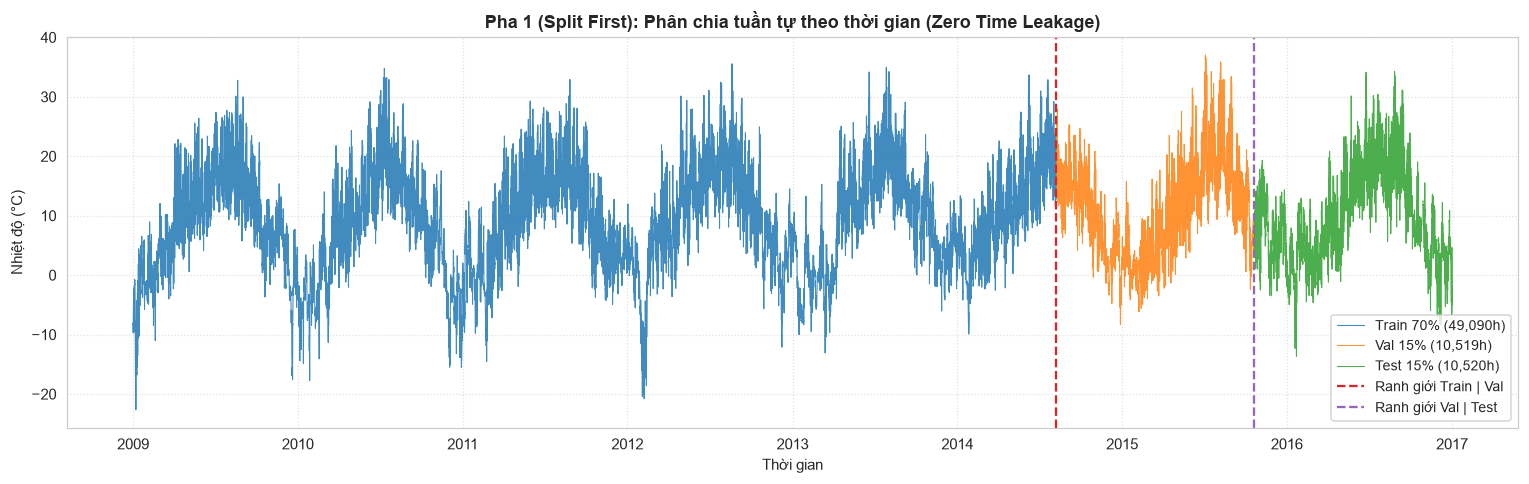

In [3]:
hourly_df = dm.load_and_resample()
train_df, val_df, test_df = dm.split_data(hourly_df)

print(f"Tổng sau Resample 1h: {len(hourly_df):,} giờ")
print(f"  - Train (70%): {len(train_df):,}h ({train_df.index.min()} -> {train_df.index.max()})")
print(f"  - Val   (15%): {len(val_df):,}h ({val_df.index.min()} -> {val_df.index.max()})")
print(f"  - Test  (15%): {len(test_df):,}h ({test_df.index.min()} -> {test_df.index.max()})")

plot_data_split_timeline(train_df, val_df, test_df)

**Giải thích Biểu đồ 2 (Pha 1 — Split First):**
- **Quan sát:** 3 tập **Train (xanh dương)**, **Val (cam)**, **Test (xanh lá)** nối tiếp nhau hoàn toàn theo trục thời gian, không trộn ngẫu nhiên.
- **Ý nghĩa chống rò rỉ:** Đảm bảo $\max(\text{Train}) < \min(\text{Val}) < \max(\text{Val}) < \min(\text{Test})$. Từ đây `val_df` và `test_df` được khóa kín — mọi biểu đồ EDA bên dưới chỉ vẽ trên `train_df`.

---
## Phần 3: Pha 2 — Khám Phá Dữ Liệu Chỉ Trên Tập Train (EDA on Train Only)

In [4]:
display(train_df.describe().T[["mean", "std", "min", "50%", "max"]].round(2))

for k, v in summarize_eda_insights(train_df).items():
    print(f"  * {k}: {v}")

,mean,std,min,50%,max
p (mbar),988.66,8.29,934.91,989.11,1012.78
T (degC),9.11,8.65,-22.65,9.20,35.52
Tpot (K),283.20,8.71,250.97,283.32,309.72
Tdew (degC),4.61,6.97,-24.60,4.97,23.02
rh (%),75.94,16.46,13.68,79.17,100.00
VPmax (mbar),13.35,7.68,0.98,11.65,57.94
VPact (mbar),9.36,4.21,0.82,8.71,28.17
VPdef (mbar),3.99,4.79,0.00,2.16,41.82
sh (g/kg),5.92,2.67,0.52,5.50,18.03
H2OC (mmol/mol),9.47,4.26,0.83,8.82,28.66


  * n_rows_train: 49090
  * missing_total: 0
  * temp_mean_degC: 9.11
  * temp_median_degC: 9.2
  * temp_std_degC: 8.65
  * temp_min_degC: -22.65
  * temp_max_degC: 35.52
  * temp_skew: -0.095
  * warmest_hour: 15h (12.44°C)
  * coldest_hour: 5h (5.99°C)
  * warmest_month: Tháng 7 (18.97°C)
  * coldest_month: Tháng 1 (-0.78°C)
  * top_positive_corr: {'Tpot (K)': 0.997, 'VPmax (mbar)': 0.95, 'Tdew (degC)': 0.902}
  * top_negative_corr: {'p (mbar)': -0.028, 'rh (%)': -0.563, 'rho (g/m**3)': -0.965}
  * autocorrelation: {'lag_24h': 0.9222, 'lag_48h': 0.8672, 'lag_72h': 0.8309, 'lag_168h': 0.7721}


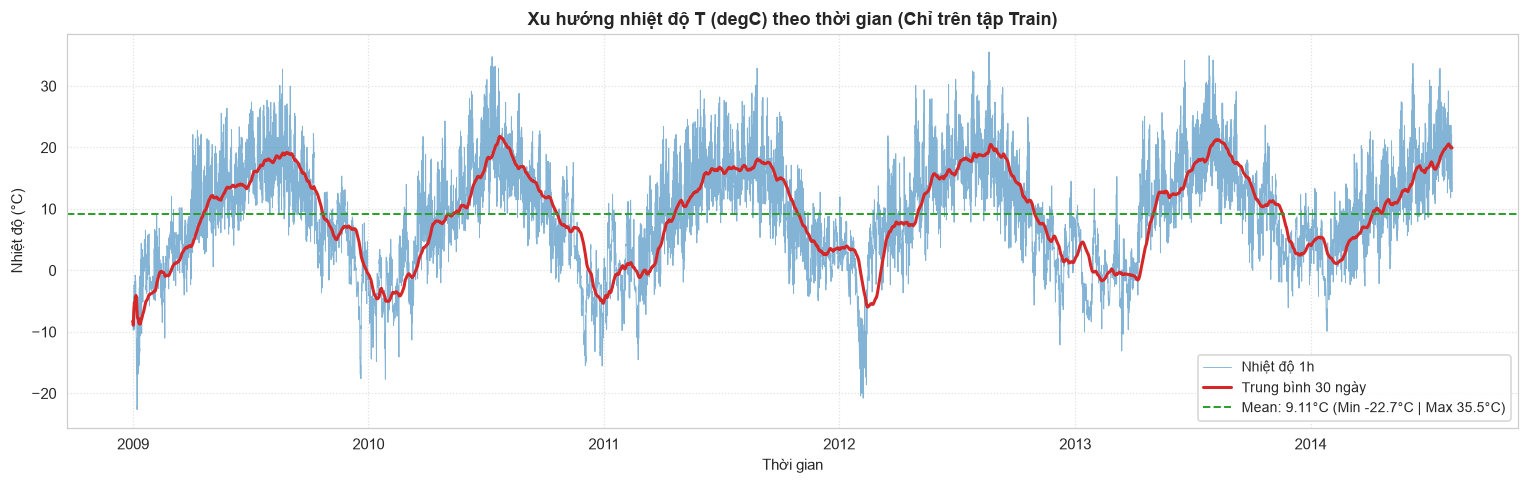

In [5]:
# Biểu đồ 3: Xu hướng nhiệt độ dài hạn + trung bình trượt 30 ngày
plot_temperature_trend(train_df)

**Giải thích Biểu đồ 3 (Xu hướng nhiệt độ dài hạn):**
- **Quan sát:** Nhiệt độ dao động hình sin lặp lại đều đặn theo chu kỳ **1 năm** (mùa hè lên tới `+35.5°C`, mùa đông xuống `-22.7°C`, trung bình `9.11°C`).
- **Ý nghĩa cho mô hình:** Chuỗi có tính mùa vụ mạnh (non-stationary) $\Rightarrow$ dùng đầu vào **168 giờ (7 ngày)** giúp mô hình nắm bắt đúng mặt bằng nhiệt độ của mùa hiện tại và xu hướng tăng/giảm ngắn hạn.

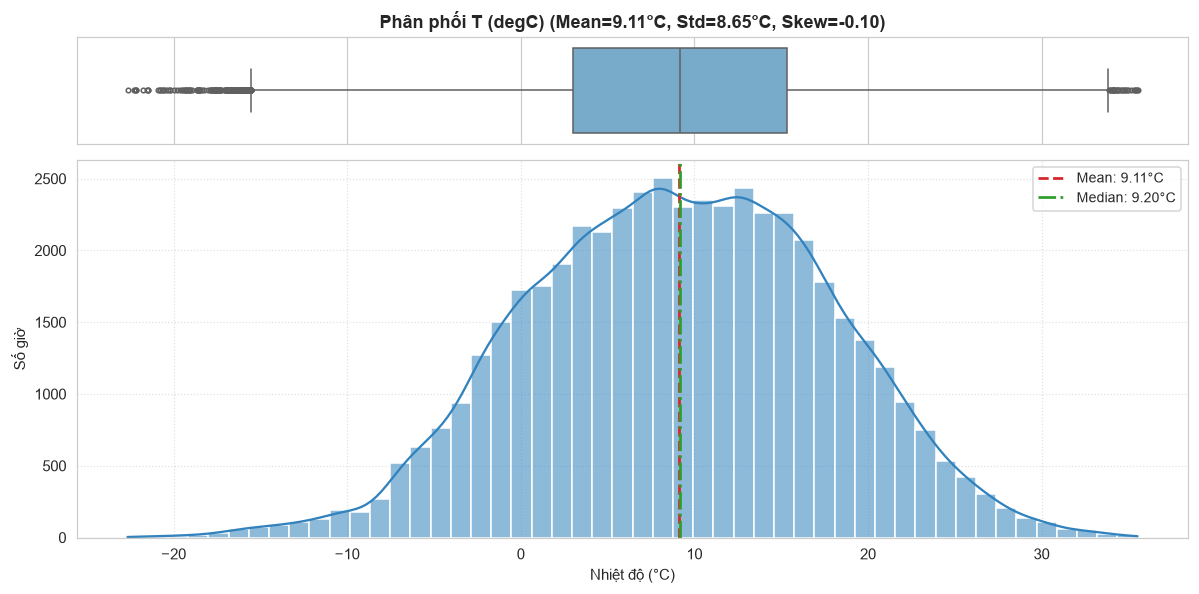

In [6]:
# Biểu đồ 4: Phân phối nhiệt độ T (degC)
plot_temperature_distribution(train_df)

**Giải thích Biểu đồ 4 (Phân phối nhiệt độ `T (degC)`):**
- **Quan sát:** Phân phối trải rộng (`Std = 8.65°C`), khá đối xứng (`Mean = 9.11°C ≈ Median = 9.20°C`, `Skew = -0.095`), có một ít điểm cực trị rét sâu ở đuôi trái (`< -15°C`).
- **Ý nghĩa cho mô hình:** Biên độ nhiệt rất rộng nên tiêu chí tỷ lệ giờ dự báo lệch $\le \pm 1.5^\circ\text{C}$ cùng `MAE`/`RMSE`/`R²` là thước đo rất chặt chẽ.

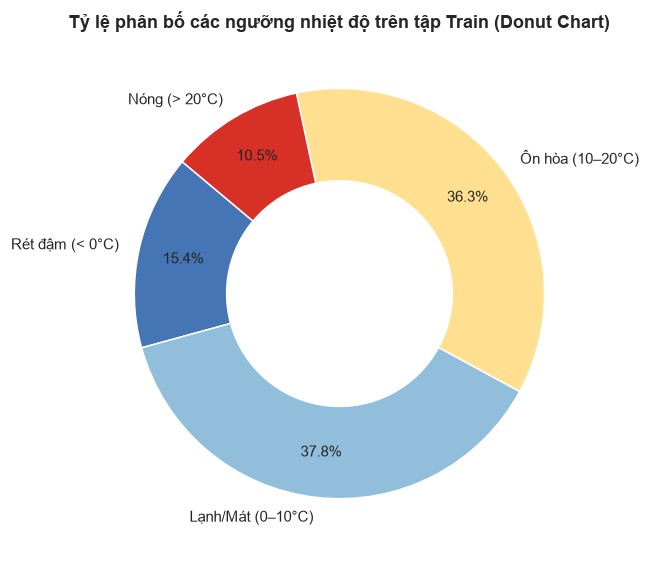

In [7]:
# Biểu đồ 5 (Donut): Tỷ lệ phân bố 4 ngưỡng nhiệt độ trên tập Train
plot_temperature_regime_pie(train_df)

**Giải thích Biểu đồ 5 (Biểu đồ tròn / Donut — Ngưỡng nhiệt độ):**
- **Quan sát:** Phần lớn thời gian trong năm tại Jena rơi vào vùng **Lạnh/Mát (`0–10°C`)** và **Ôn hòa (`10–20°C`)**, còn **Rét đậm (`< 0°C`)** và **Nóng (`> 20°C`)** chiếm tỷ lệ nhỏ hơn nhưng tạo ra biến động lớn.
- **Ý nghĩa cho mô hình:** Dữ liệu không mất cân bằng cực đoan ở dải giữa, nhưng vùng rét đậm và nắng nóng ít mẫu hơn $\Rightarrow$ cần theo dõi sai số ở các ngày cực đoan khi đánh giá.

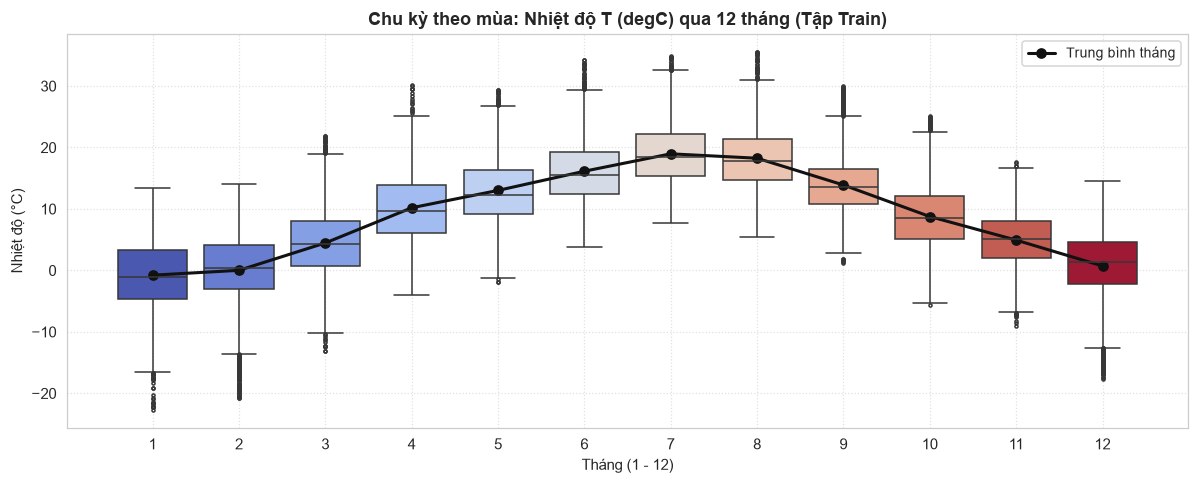

In [8]:
# Biểu đồ 5: Chu kỳ theo 12 tháng trong năm
plot_seasonal_monthly_cycle(train_df)

**Giải thích Biểu đồ 5 (Chu kỳ 12 tháng):**
- **Quan sát:** Hình chuông rõ rệt — lạnh nhất vào **tháng 1 (`-0.78°C`)**, nóng nhất vào **tháng 7 (`18.97°C`)**.
- **Ý nghĩa cho mô hình:** Độ rộng hộp Boxplot lớn ở mùa đông/xuân cho thấy biến động nhiệt đột ngột mạnh $\Rightarrow$ cần kết hợp thêm các biến khí tượng khác (áp suất, độ ẩm, gió) chứ không chỉ nhìn mỗi nhiệt độ.

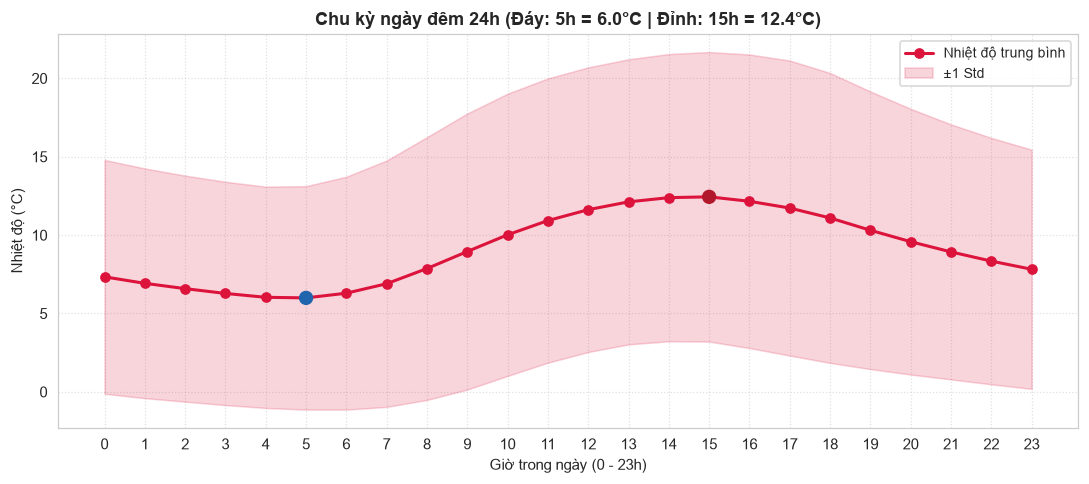

In [9]:
# Biểu đồ 6: Chu kỳ ngày đêm 24 giờ
plot_diurnal_cycle(train_df)

**Giải thích Biểu đồ 6 (Chu kỳ ngày đêm 24 giờ):**
- **Quan sát:** Nhiệt độ đạt **đáy lúc 5h sáng (`5.99°C`)** và **đỉnh lúc 15h chiều (`12.44°C`)** (biên độ ngày-đêm trung bình ~`6.5°C`).
- **Ý nghĩa cho mô hình:** Dự báo **72 giờ = đúng 3 chu kỳ ngày-đêm liên tiếp**, mô hình phải học tốt nhịp lên-xuống 24h này.

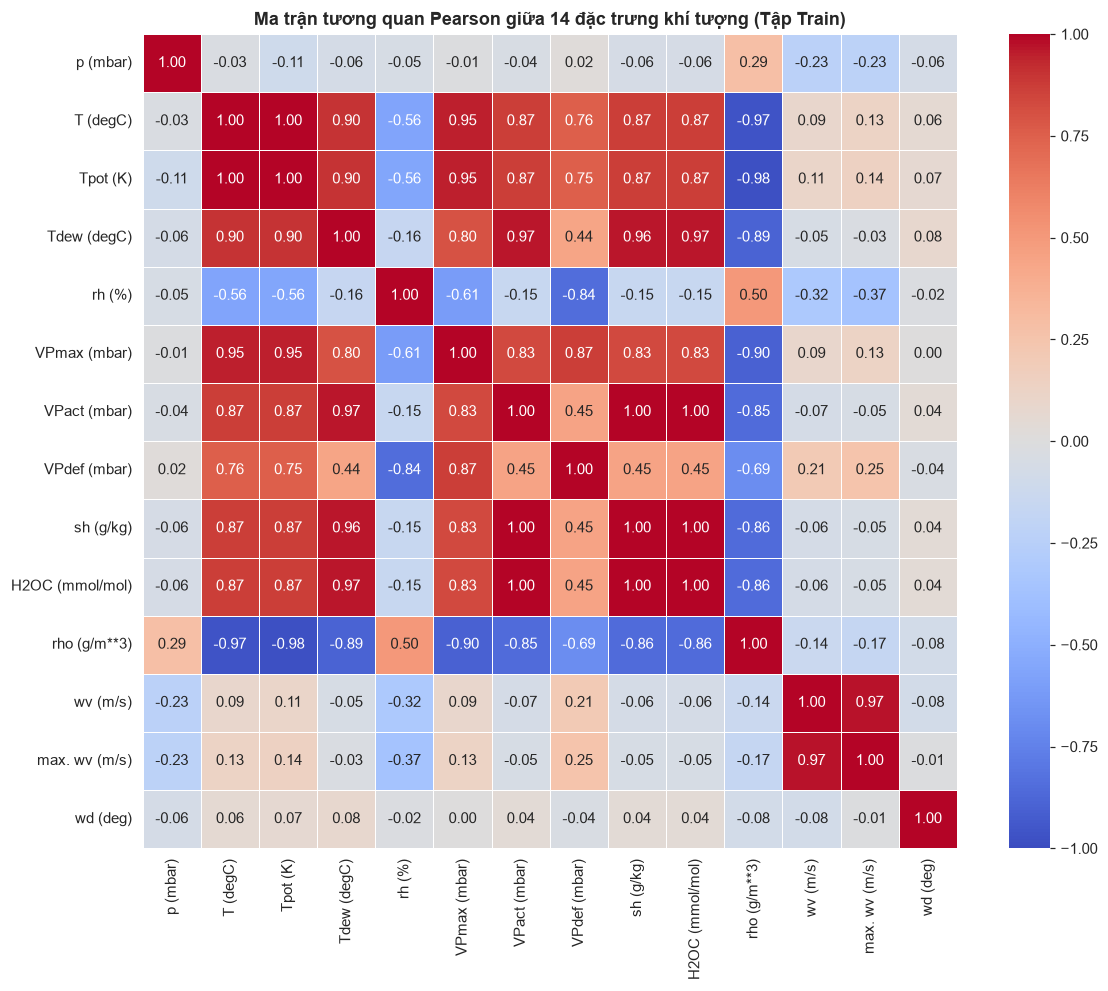

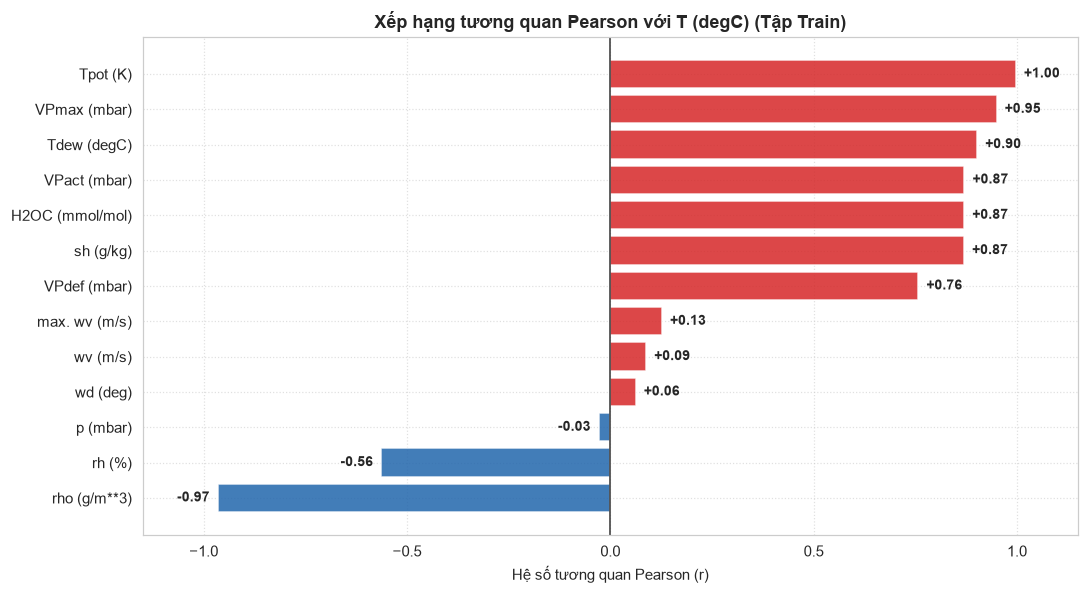

In [10]:
# Biểu đồ 7 & 8: Ma trận tương quan 14 biến & Xếp hạng tương quan với T (degC)
plot_correlation_heatmap(train_df)
plot_target_correlations(train_df)

**Giải thích Biểu đồ 7 & 8 (Tương quan giữa 14 đặc trưng khí tượng):**
- **Tương quan thuận rất mạnh ($r > 0.90$):** `Tpot (K)` (`+0.997`), `VPmax (mbar)` (`+0.950`), `Tdew (degC)` (`+0.902`) cùng nhóm độ ẩm tuyệt đối (`VPact`, `sh`, `H2OC`).
- **Tương quan nghịch rất mạnh:** `rho (g/m**3)` (`-0.965`, không khí nóng thì loãng hơn) và `rh (%)` (`-0.563`).
- **Biến tương quan tuyến tính yếu (`p`, `wv`, `wd`):** Mang tín hiệu phi tuyến quan trọng báo trước không khí lạnh/mưa bão $\Rightarrow$ giữ đủ **14 biến đầu vào** cho mạng học sâu.

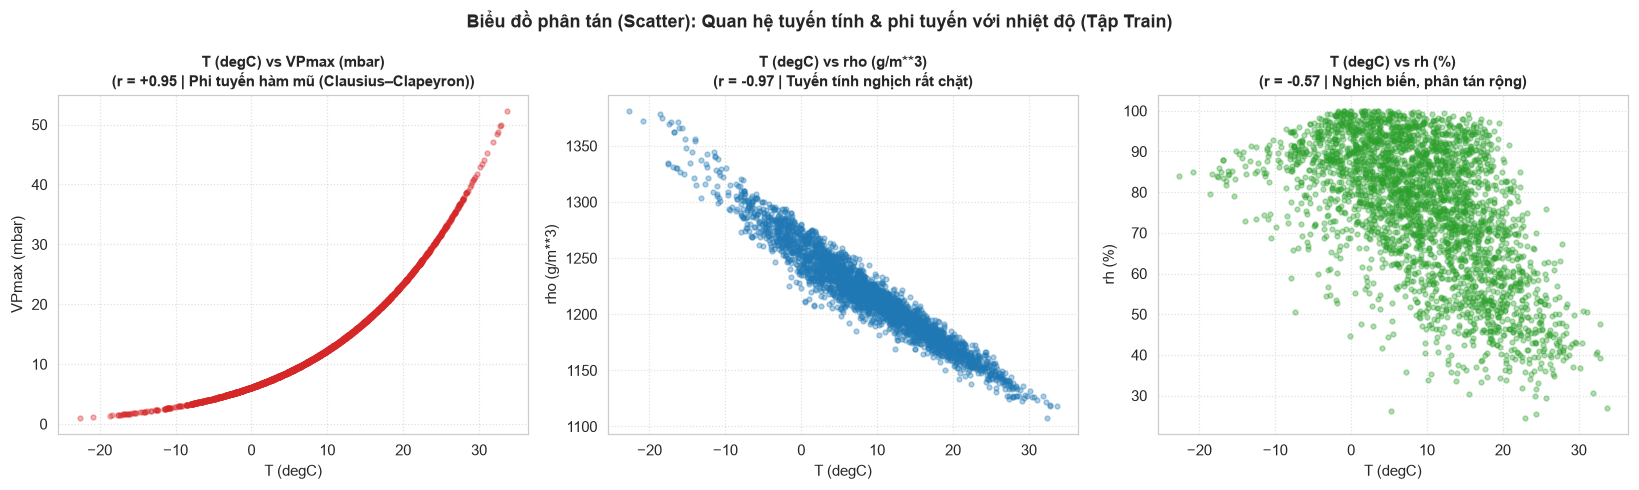

In [11]:
# Biểu đồ phân tán (Scatter): Quan hệ tuyến tính & phi tuyến với T (degC)
plot_scatter_relationships(train_df)

**Giải thích Biểu đồ phân tán (Scatter Plot — `T` vs `VPmax`, `rho`, `rh`):**
- **Quan sát:**
  - `T` vs `VPmax (mbar)` tạo **đường cong hàm mũ phi tuyến** rất sắc nét (định luật vật lý Clausius–Clapeyron).
  - `T` vs `rho (g/m**3)` tạo đường thẳng giảm tuyến tính rất chặt ($r \approx -0.96$).
  - `T` vs `rh (%)` có xu hướng giảm nhưng phân tán rộng theo độ ẩm từng ngày.
- **Ý nghĩa cho mô hình (điểm nhấn vấn đáp):** Chứng minh trực quan rằng mối quan hệ khí tượng mang tính **phi tuyến mạnh** $\Rightarrow$ lý giải vì sao cần dùng **Deep Learning (LSTM / Attention / Transformer)** thay vì các mô hình tuyến tính đơn giản.

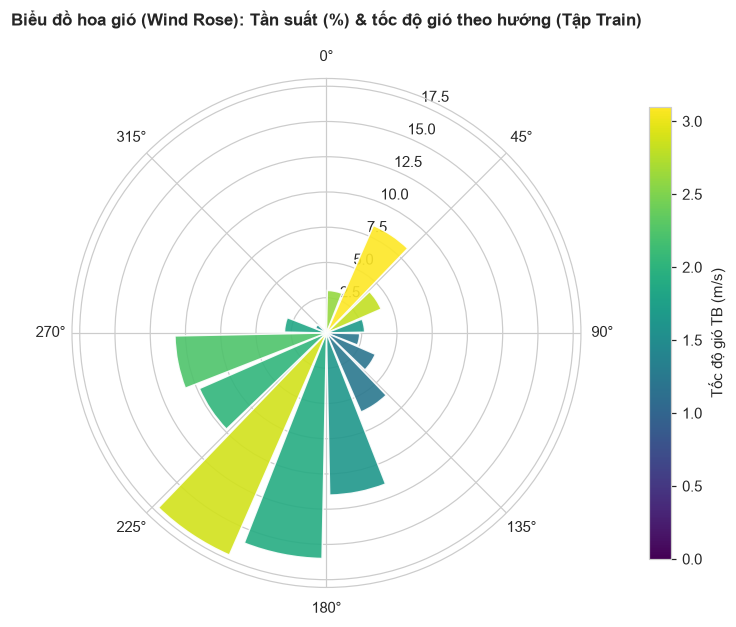

In [12]:
# Biểu đồ hoa gió (Polar Wind Rose): Hướng gió wd (deg) & tốc độ gió wv (m/s)
plot_wind_rose(train_df)

**Giải thích Biểu đồ hoa gió (Wind Rose — `wd` & `wv`):**
- **Quan sát:** Gió tại Jena thổi chủ yếu theo hướng **Tây Nam (SW)** và **Đông Bắc (NE)**, với gió Tây Nam có tốc độ trung bình lớn nhất.
- **Ý nghĩa cho mô hình:** Vì `wd (deg)` là biến góc tuần hoàn (`0° ≡ 360°`), biểu đồ hoa gió phản ánh đúng bản chất vật lý hơn tương quan Pearson tuyến tính.

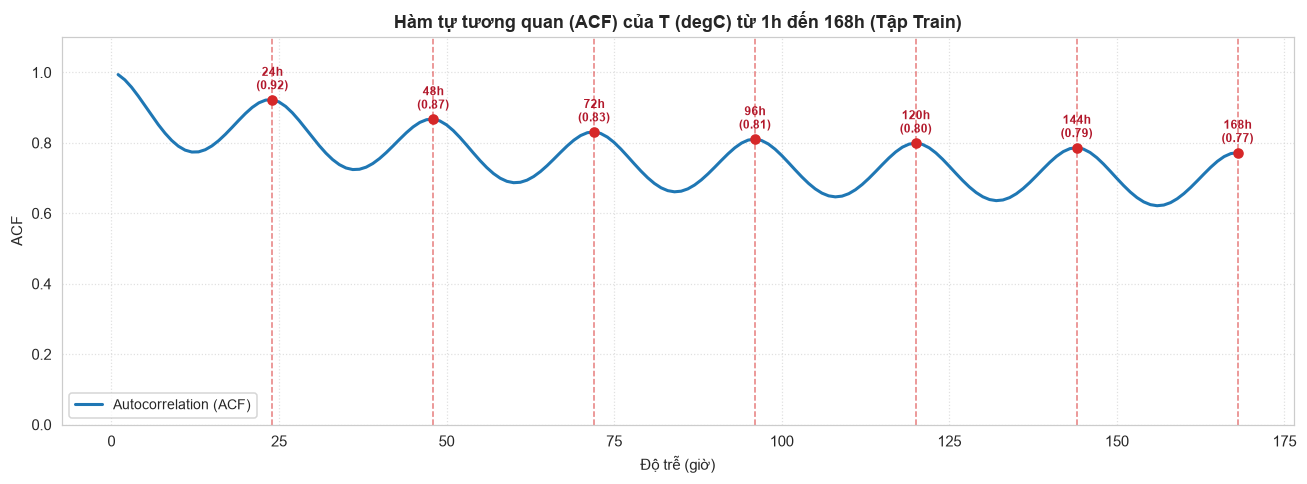

In [13]:
# Biểu đồ 9: Hàm tự tương quan ACF (1h -> 168h)
plot_autocorrelation(train_df, max_lag=168)

**Giải thích Biểu đồ 9 (Hàm tự tương quan ACF 1h – 168h — điểm nhấn kiến trúc):**
- **Quan sát:** Các đỉnh tương quan lặp lại đúng mỗi **24 giờ**: `24h (0.92)`, `48h (0.87)`, `72h (0.83)`, ..., `168h (0.77)`.
- **Ý nghĩa trực tiếp cho mô hình:**
  1. **Lý giải chọn `168h -> 72h`:** Sau 7 ngày (168h) nhiệt độ vẫn giữ tự tương quan rất cao (`0.77`).
  2. **Lý giải vì sao Attention & Transformer vượt trội Baseline LSTM:** LSTM thường nén 168 giờ vào 1 vector ẩn dễ quên thông tin xa, còn **Bahdanau Attention** và **Transformer** có thể nhìn thẳng vào các đỉnh `24h, 48h, ..., 168h` tương ứng trong quá khứ.

---
## Phần 4: Pha 3 & Pha 4 — Chuẩn Hóa, Cửa Sổ Trượt & Kiểm Định Zero Leakage

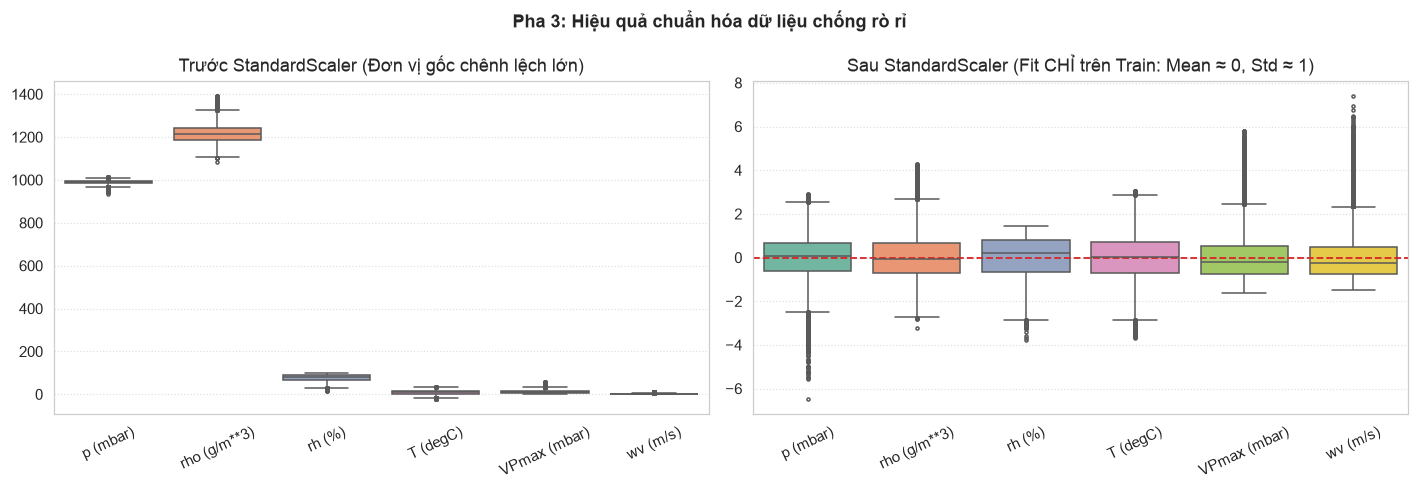

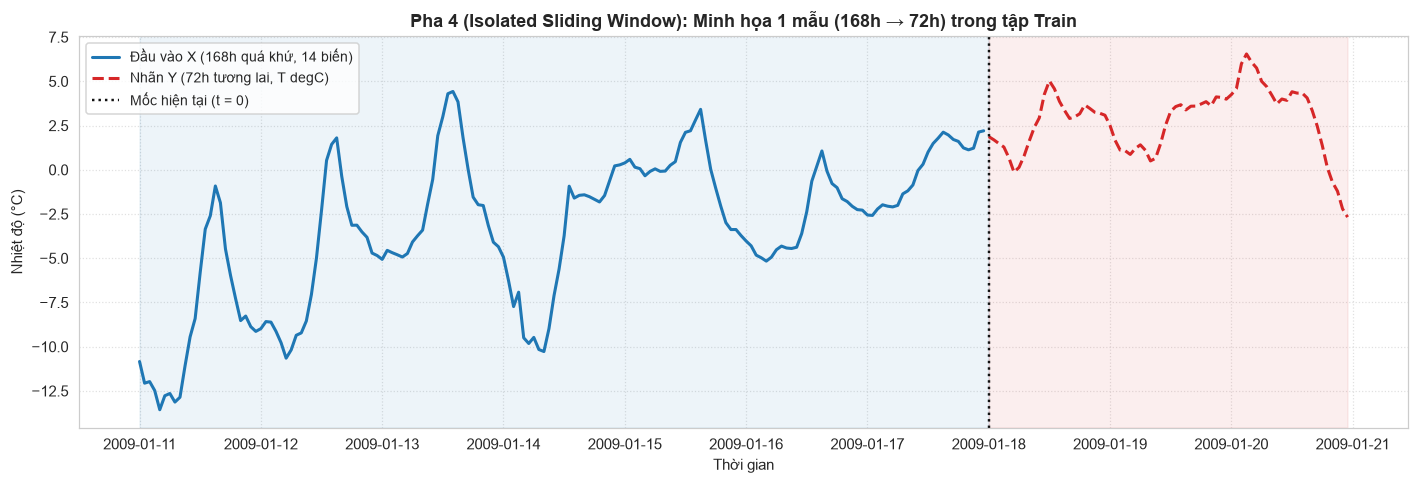

In [14]:
dm.setup()
train_scaled, _, _ = dm.fit_scaler_and_impute()

# Biểu đồ 10: Trước & Sau StandardScaler (fit chỉ trên Train)
plot_scaling_comparison(dm.train_df.ffill().bfill(), train_scaled, dm.features)

# Biểu đồ 11: Minh họa 1 mẫu Sliding Window (168h -> 72h) nội bộ Train
plot_sliding_window_example(dm.train_df.ffill().bfill(), seq_len=dm.seq_len, pred_len=dm.pred_len, start_idx=240)

In [15]:
# Kiểm định tự động Zero Data Leakage & Shape DataLoader
assert dm.verify_zero_leakage() is True
train_loader, val_loader, test_loader = dm.get_dataloaders(batch_size=cfg["batch_size"], num_workers=0)
x_b, y_b = next(iter(train_loader))

print(f"[PASS] Zero Leakage: scaler.n_samples_seen_ ({int(dm.scaler.n_samples_seen_):,}) == len(train_df) ({len(dm.train_df):,})")
print(f"[PASS] Tensor Shape: X = {tuple(x_b.shape)}, Y = {tuple(y_b.shape)}")
print(f"[PASS] Sliding Windows: Train={len(dm.train_dataset):,} | Val={len(dm.val_dataset):,} | Test={len(dm.test_dataset):,}")
print(f"[PASS] Giải chuẩn hóa (°C) 5 giờ đầu mẫu 0: {np.round(dm.inverse_transform_target(y_b[:1])[0, :5, 0], 2)}")

[PASS] Zero Leakage: scaler.n_samples_seen_ (49,090) == len(train_df) (49,090)
[PASS] Tensor Shape: X = (64, 168, 14), Y = (64, 72, 1)
[PASS] Sliding Windows: Train=48,851 | Val=10,280 | Test=10,281
[PASS] Giải chuẩn hóa (°C) 5 giờ đầu mẫu 0: [13.29 12.94 12.36 12.15 12.32]


**Giải thích Biểu đồ 10 & 11 + Chốt ý Chương 3:**
- **Biểu đồ 10 (`StandardScaler`):** Đưa toàn bộ 14 biến từ thang đo chênh lệch hàng trăm lần (`rho ~1200`, `p ~990` vs `wv ~2`) về cùng chuẩn **Mean ≈ 0, Std ≈ 1** (chỉ học tham số từ Train) giúp mạng hội tụ ổn định.
- **Biểu đồ 11 (Sliding Window):** Mỗi mẫu gồm **168h quá khứ (xanh)** $\rightarrow$ **72h tương lai (đỏ)** cắt độc lập trong từng tập Train/Val/Test, đạt **Zero Leakage 100%** và sẵn sàng chuyển sang Chương 4 (xây dựng & huấn luyện 3 mô hình).

---
## Phần 5: Tổng Kết Tiền Xử Lý & Ghi Chú Feature Engineering (Chuẩn Bị Vấn Đáp)

1. **5 bước Tiền xử lý / Biến đổi đặc trưng đã triển khai trong `src/data_module.py`:**
   - Lọc lỗi cảm biến gió (`-9999.0 -> NaN`).
   - Gom mẫu thời gian `resample(1h).mean()` (giảm nhiễu 10 phút và giảm độ dài chuỗi 6 lần).
   - Điền khuyết nội bộ từng tập (`ffill().bfill()`).
   - Chuẩn hóa `StandardScaler` chỉ `fit` trên tập Train.
   - Đóng gói cửa sổ trượt độc lập `(168h × 14) -> (72h × 1)`.
2. **Hướng Feature Engineering mở rộng (Future Work — không thay đổi để giữ cố định `input_dim = 14` cho toàn nhóm):**
   - **Vector gió 2D:** $W_x = wv \cdot \cos(\text{wd}_{\text{rad}})$, $W_y = wv \cdot \sin(\text{wd}_{\text{rad}})$ để khắc phục tính gián đoạn `0°/360°` của `wd (deg)`.
   - **Mã hóa chu kỳ thời gian:** `Day sin/cos` (24h) và `Year sin/cos` (365.2425 ngày) để mô hình nhận biết trực tiếp khung giờ trong ngày và mùa trong năm.